In [2]:
import seaborn as sns
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython import display
display.set_matplotlib_formats('svg')

/tmp/ipykernel_1269/1120299142.py:8: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  display.set_matplotlib_formats('svg')


In [3]:
iris = sns.load_dataset('iris')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
data = torch.tensor(iris[iris.columns[0:4]].values).float()
labels = torch.zeros(len(data), dtype=torch.long)
labels[iris.species=='versicolor']=1
labels[iris.species=='virginica']=2
labels

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2])

In [10]:
# create class for model
class ANNiris(nn.Module):
    def __init__(self, nUnits, nLayers):
        super().__init__()
        # creating dictionaries to store the layers
        self.layers = nn.ModuleDict()
        self.nLayers = nLayers
        # Input layer
        self.layers['input'] = nn.Linear(4, nUnits)
        # Hidden layers
        for i in range(nLayers):
            self.layers[f'hidden{i}'] = nn.Linear(nUnits, nUnits)
        # Output layers
        self.layers['output'] = nn.Linear(nUnits, 3)
    # Forward pass
    def forward(self, x):
        x = self.layers['input'](x)
        for i in range(self.nLayers):
            x = F.relu(self.layers[f'hidden{i}'](x))
        x = self.layers['output'](x)
        return x

In [11]:
nUnitsPerLayer = 12
nLayers = 4
net = ANNiris(nUnitsPerLayer, nLayers)
net

ANNiris(
  (layers): ModuleDict(
    (input): Linear(in_features=4, out_features=12, bias=True)
    (hidden0): Linear(in_features=12, out_features=12, bias=True)
    (hidden1): Linear(in_features=12, out_features=12, bias=True)
    (hidden2): Linear(in_features=12, out_features=12, bias=True)
    (hidden3): Linear(in_features=12, out_features=12, bias=True)
    (output): Linear(in_features=12, out_features=3, bias=True)
  )
)

In [12]:
from torchsummary import summary
net = net.to('cuda')
summary(net, (4,), device='cuda')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 12]              60
            Linear-2                   [-1, 12]             156
            Linear-3                   [-1, 12]             156
            Linear-4                   [-1, 12]             156
            Linear-5                   [-1, 12]             156
            Linear-6                    [-1, 3]              39
Total params: 723
Trainable params: 723
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [13]:
print("Hidden layers:", net.nLayers)
print("Available layers:", list(net.layers.keys()))

Hidden layers: 4
Available layers: ['input', 'hidden0', 'hidden1', 'hidden2', 'hidden3', 'output']


In [17]:
# quick test to check the if the architecture is internally consistent
tmpx = torch.randn(10,4, device = 'cuda')
y = net(tmpx)
print(y.shape), print('')
print(y)

torch.Size([10, 3])

tensor([[ 0.3047,  0.3867, -0.3054],
        [ 0.3058,  0.3881, -0.3049],
        [ 0.3059,  0.3951, -0.3070],
        [ 0.3066,  0.3923, -0.3067],
        [ 0.3073,  0.3869, -0.3067],
        [ 0.3031,  0.3977, -0.3087],
        [ 0.3047,  0.3842, -0.3042],
        [ 0.3054,  0.3855, -0.3056],
        [ 0.3045,  0.4028, -0.3122],
        [ 0.2952,  0.4008, -0.3099]], device='cuda:0',
       grad_fn=<AddmmBackward0>)


In [24]:
# Function to train the model
def trainTheModel(theModel):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    theModel = theModel.to(device)
    data_device = data.to(device)
    labels_device = labels.to(device)

    lossfun = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(theModel.parameters(), lr=0.1)

    for epochi in range(numepochs):

        yhat = theModel(data_device)

        loss = lossfun(yhat, labels_device)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    predictions = theModel(data_device)

    predlabels = torch.argmax(predictions, axis=1)

    acc = 100 * torch.mean((predlabels == labels_device).float())

    nParams = sum(p.numel() for p in theModel.parameters() if p.requires_grad)

    return acc.item(), nParams

In [25]:
numepochs = 2500
acc = trainTheModel(net)

acc

(96.66667175292969, 723)

In [27]:
numlayers = range(1,6)
numunits = np.arange(4,101,3)

accuracies = np.zeros((len(numunits), len(numlayers)))
totalparams = np.zeros((len(numunits), len(numlayers)))

numepochs = 500

for unitidx in range(len(numunits)):
    for layeridx in range(len(numlayers)):
        net = ANNiris(numunits[unitidx], numlayers[layeridx])
        acc, nParams = trainTheModel(net)
        accuracies[unitidx, layeridx] = acc
        totalparams[unitidx, layeridx] = nParams



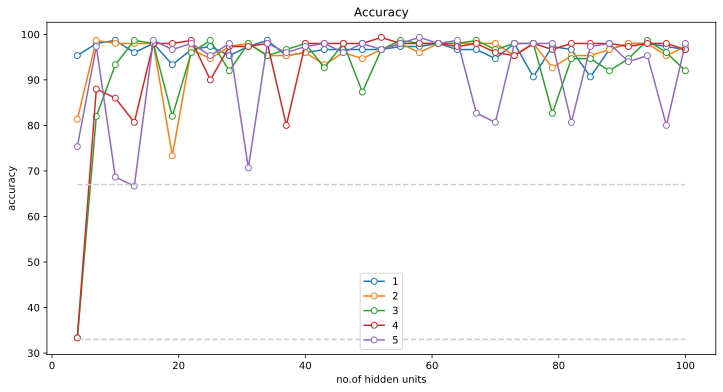

In [29]:
fig,ax = plt.subplots(1, figsize=(12,6))
ax.plot(numunits,accuracies,'o-',markerfacecolor='w')
ax.plot(numunits[[0,-1]],[33,33],'--',color=[.8,.8,.8])
ax.plot(numunits[[0,-1]],[67,67],'--',color=[.8,.8,.8])
ax.legend(numlayers)
ax.set_ylabel('accuracy')
ax.set_xlabel('no.of hidden units')
ax.set_title('Accuracy')
plt.show()

In [31]:
totalparams.shape

(33, 5)

In [32]:
totalparams.flatten().shape

(165,)

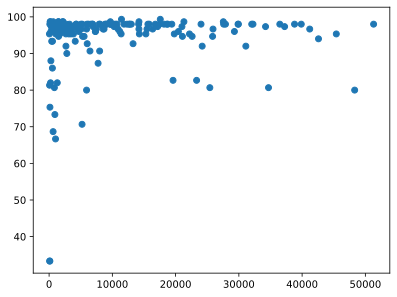

In [34]:
x = totalparams.flatten()
y = accuracies.flatten()
r = np.corrcoef(x,y)[0,1]
plt.plot(x,y,'o')
plt.show()